In [1]:
import networkx as nx

import numpy as np
import matplotlib.pyplot as plt 
from math import comb, factorial
from itertools import combinations
from functools import partial

from typing import Union

from tabulate import tabulate
import pandas as pd

from scipy.linalg import sqrtm,eig


import perceval as pcvl
import exqalibur as xqlbr

from BSutils import *

In [2]:

# adj = np.array([
#   [0,1,1,1,1,0,0,1],
#   [1,0,1,0,1,1,0,0],
#   [1,1,0,1,0,1,0,0],
#   [1,0,1,0,1,0,1,0],
#   [1,1,0,1,0,0,0,0],
#   [0,1,1,0,0,0,0,0],
#   [0,0,0,1,0,0,0,0],
#   [1,0,0,0,0,0,0,0]
# ])


# # adj = np.array([
# #   [0,0,0,0,0,0,1,0,1,1,1,0],
# #   [0,0,1,0,0,1,0,0,0,1,0,1],
# #   [0,1,0,1,1,0,1,0,0,0,1,1],
# #   [0,0,1,0,1,1,1,0,1,1,1,1],
# #   [0,0,1,1,0,0,1,1,1,1,1,1],
# #   [0,1,0,1,0,0,1,1,0,1,1,0],
# #   [1,0,1,1,1,1,0,0,0,0,1,0],
# #   [0,0,0,0,1,1,0,0,0,1,0,1],
# #   [1,0,0,1,1,0,0,0,0,1,0,0],
# #   [1,1,0,1,1,1,0,1,1,0,1,0],
# #   [1,0,1,1,1,1,1,0,0,1,0,0],
# #   [0,1,1,1,1,0,0,1,0,0,0,0]
# # ])

# # adj = np.array([
# #   [0,0,1,1,0,1,1,1,1,0],
# #   [0,0,1,1,1,0,1,1,1,0],
# #   [1,1,0,1,0,0,0,0,1,1],
# #   [1,1,1,0,1,1,0,1,1,0],
# #   [0,1,0,1,0,1,0,0,0,1],
# #   [1,0,0,1,1,0,0,0,1,0],
# #   [1,1,0,0,0,0,0,0,0,0],
# #   [1,1,0,1,0,0,0,0,1,1],
# #   [1,1,1,1,0,1,0,1,0,1],
# #   [0,0,1,0,1,0,0,1,1,0]
# # ])


# # adj = np.array([
# #   [0,0,0,0,0,0,1,0,1,1,1,0],
# #   [0,0,1,0,0,1,0,0,0,1,0,1],
# #   [0,1,0,1,1,0,1,0,0,0,1,1],
# #   [0,0,1,0,1,1,1,0,1,1,1,1],
# #   [0,0,1,1,0,0,1,1,1,1,1,1],
# #   [0,1,0,1,0,0,1,1,0,1,1,0],
# #   [1,0,1,1,1,1,0,0,0,0,1,0],
# #   [0,0,0,0,1,1,0,0,0,1,0,1],
# #   [1,0,0,1,1,0,0,0,0,1,0,0],
# #   [1,1,0,1,1,1,0,1,1,0,1,0],
# #   [1,0,1,1,1,1,1,0,0,1,0,0],
# #   [0,1,1,1,1,0,0,1,0,0,0,0]
# # ])



# # adj = np.array([
# #   [0,1,0,0,1,1,1,0,1,1],
# #   [1,0,1,0,0,0,1,1,1,1],
# #   [0,1,0,1,0,1,0,1,1,1],
# #   [0,0,1,0,1,0,0,1,1,0],
# #   [1,0,0,1,0,1,0,1,0,1],
# #   [1,0,1,0,1,0,0,0,1,0],
# #   [1,1,0,0,0,0,0,0,1,1],
# #   [0,1,1,1,1,0,0,0,1,0],
# #   [1,1,1,1,0,1,1,1,0,0],
# #   [1,1,1,0,1,0,1,0,0,0]
# # ])

# # adj = np.array([
# #   [0,1,1,1,0,0,0,0,0,0,0,0],
# #   [1,0,1,1,1,0,0,0,1,0,0,0],
# #   [1,1,0,1,0,0,0,0,1,0,0,1],
# #   [1,1,1,0,0,0,0,0,0,0,0,0],
# #   [0,1,0,0,0,0,0,0,1,0,0,0],
# #   [0,0,0,0,0,0,0,0,0,0,0,1],
# #   [0,0,0,0,0,0,0,1,1,1,1,1],
# #   [0,0,0,0,0,0,1,0,1,1,1,1],
# #   [0,1,1,0,1,0,1,1,0,1,1,1],
# #   [0,0,0,0,0,0,1,1,1,0,1,1],
# #   [0,0,0,0,0,0,1,1,1,1,0,1],
# #   [0,0,1,0,0,1,1,1,1,1,1,0]
# # ])


# # new

# # adj = np.array([
# #   [0,1,1,1,1,1,0,0,0,0,0,0],
# #   [1,0,1,1,1,1,0,0,1,0,0,0],
# #   [1,1,0,1,0,0,0,0,1,0,0,1],
# #   [1,1,1,0,0,0,0,0,0,0,0,0],
# #   [1,1,0,0,0,1,0,0,0,0,0,0],
# #   [1,1,0,0,1,0,0,0,0,0,0,0],
# #   [0,0,0,0,0,0,0,1,1,1,1,1],
# #   [0,0,0,0,0,0,1,0,1,1,1,1],
# #   [0,1,1,0,0,0,1,1,0,1,1,1],
# #   [0,0,0,0,0,0,1,1,1,0,1,1],
# #   [0,0,0,0,0,0,1,1,1,1,0,1],
# #   [0,0,1,0,0,0,1,1,1,1,1,0]
# # ])


# adj = np.array([
#   [0,1,1,1,0,0,1,0,0,0],
#   [1,0,1,0,1,1,0,0,1,1],
#   [1,1,0,0,0,0,1,0,0,1],
#   [1,0,0,0,1,0,1,1,1,1],
#   [0,1,0,1,0,1,0,1,0,1],
#   [0,1,0,0,1,0,1,0,0,1],
#   [1,0,1,1,0,1,0,1,1,0],
#   [0,0,0,1,1,0,1,0,1,1],
#   [0,1,0,1,0,0,1,1,0,1],
#   [0,1,1,1,1,1,0,1,1,0]
# ])

# np.where(adj!=adj.transpose())

# G = nx.Graph()
# for i in range(len(adj)):
#    G.add_node(i)
   
# for i in range(len(adj)): 
#  for j in range(len(adj)): 
#    if adj[i][j] == 1: 
#       G.add_edge(i,j) 







### Graph definition

In [3]:
nodes = 12
parameter = 0.5

In [4]:

G = nx.erdos_renyi_graph(nodes,p=parameter)


pos = nx.spring_layout(G, seed=42)

adj = nx.adjacency_matrix(G).toarray()

print(adj)



[[0 1 1 0 0 1 1 1 0 1 1 0]
 [1 0 0 1 0 0 0 1 0 0 1 0]
 [1 0 0 0 0 1 0 1 0 0 1 0]
 [0 1 0 0 0 1 0 0 1 0 1 1]
 [0 0 0 0 0 0 1 1 0 0 1 1]
 [1 0 1 1 0 0 1 0 1 1 1 1]
 [1 0 0 0 1 1 0 1 1 0 0 1]
 [1 1 1 0 1 0 1 0 1 1 0 1]
 [0 0 0 1 0 1 1 1 0 0 1 1]
 [1 0 0 0 0 1 0 1 0 0 0 0]
 [1 1 1 1 1 1 0 0 1 0 0 0]
 [0 0 0 1 1 1 1 1 1 0 0 0]]


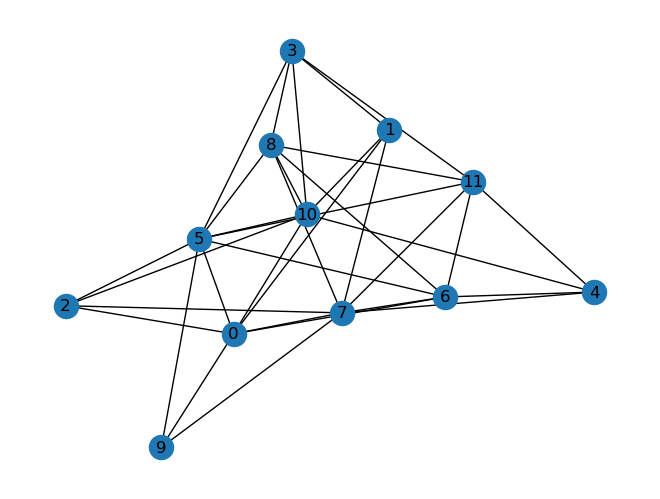

In [5]:

nx.draw( G , with_labels = True,pos=pos) 
plt.show()

### Boson Sampling results

In [6]:
n = nodes
k = n//2
# k = 5
print(n,"nodes")
print(comb(n,k), "subgraphs of size", k)




12 nodes
924 subgraphs of size 6


In [7]:

select_out = np.array(
    [
        [1 if i in comb else 0 for i in range(n)]
        for comb in combinations(np.arange(n), k)
    ]
    )

#For multiple application of U_A

# vals,_ = eig(adj)
# print(vals[0])
# adjbis = adj/vals[0]
# D = sqrtm(np.eye(len(adj)) - adjbis*adjbis.conjugate())
# res = [(o,np.abs(superposition_perm(adjbis@adjbis+D*D,o)[0])) for o in select_out ]


res = [(o,np.abs(superposition_perm(adj,o)[0])) for o in select_out ]

res.sort(key=lambda x: x[1])
print("Total value of permanents (without V matrix)", res[-1])


res_pure = [(o,np.abs(perm_estimation_graph(adj,o))) for o in select_out ]
# offdiag_res = [(o,np.abs(perm_estimation_graph(G,o))) for o in select_out ]

res_pure.sort(key=lambda x: x[1])
print("Pure value of permanent ",res_pure[-1])



Total value of permanents (without V matrix) (array([1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0]), np.float64(29316.0))
Pure value of permanent  (array([1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1]), np.float64(72.0))


Pure permanent values


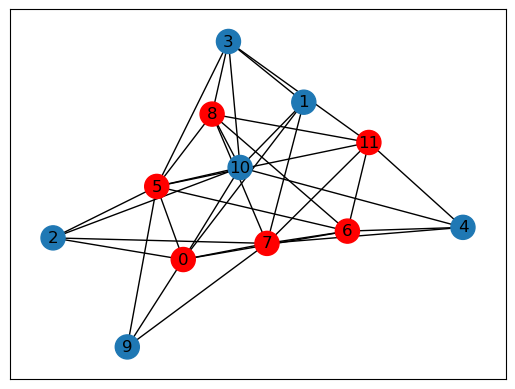

In [8]:

colours = ['#1f78b4' if i==0 else 'red' for i in res_pure[-1][0]]

nx.draw_networkx(G, node_color=colours,pos=pos)
print("Pure permanent values")
plt.show()

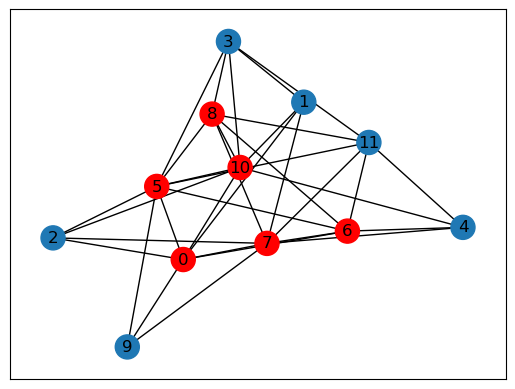

In [9]:

colours = ['#1f78b4' if i==0 else 'red' for i in res[-1][0]]

nx.draw_networkx(G, node_color=colours,pos=pos)
plt.show()

In [10]:
header = ["state","Permanent","Rectangular Permanent","density"]

fullres = [("".join(str(i) for i in state), val, np.abs(superposition_perm(adj,state)[0]), np.round(density(G,state),3)) 
           for state,val in res_pure]

results = pd.DataFrame(fullres,columns = header)

In [19]:

results.sort_values(by = "Permanent", ascending=False,inplace=True)

print(tabulate(results,headers=header ,tablefmt="pretty",showindex=False))
    

    

+--------------+-------+-----------+-----------------------+---------+
|              | state | Permanent | Rectangular Permanent | density |
+--------------+-------+-----------+-----------------------+---------+
| 100001111001 | 72.0  |  23826.0  |          0.8          | 21560.0 |
| 000101111001 | 57.0  |  16095.0  |          0.8          | 15400.0 |
| 000101101011 | 57.0  |  13386.0  |          0.8          | 13475.0 |
| 000011111001 | 57.0  |  11623.0  |          0.8          | 12320.0 |
| 101001011010 | 53.0  |  18968.0  |         0.733         | 16768.9 |
| 000011101011 | 53.0  |  10266.0  |         0.733         | 10780.0 |
| 100001110101 | 44.0  |  11266.0  |         0.733         | 10780.0 |
| 101001110001 | 44.0  |  15916.0  |         0.733         | 14373.3 |
| 101001111000 | 44.0  |  15252.0  |         0.733         | 14373.3 |
| 100001111010 | 44.0  |  29316.0  |         0.733         | 25153.3 |
| 100001111100 | 44.0  |  11396.0  |         0.733         | 10780.0 |
| 1101

In [12]:

results.sort_values(by = "Rectangular Permanent", ascending=False,inplace=True)

print(tabulate(results,headers=header ,tablefmt="pretty",showindex=False))
    

+--------------+-----------+-----------------------+---------+
|    state     | Permanent | Rectangular Permanent | density |
+--------------+-----------+-----------------------+---------+
| 100001111010 |   44.0    |        29316.0        |  0.733  |
| 100001011011 |   29.0    |        28552.0        |  0.667  |
| 100001110011 |   20.0    |        27779.0        |  0.667  |
| 100001111001 |   72.0    |        23826.0        |   0.8   |
| 100101010011 |   16.0    |        23607.0        |   0.6   |
| 100101011010 |   25.0    |        23154.0        |  0.667  |
| 100101110010 |   13.0    |        22762.0        |   0.6   |
| 000001111011 |   29.0    |        22679.0        |  0.733  |
| 100000111011 |   25.0    |        20547.0        |  0.667  |
| 100001101011 |   40.0    |        20438.0        |  0.733  |
| 100101110001 |   20.0    |        20211.0        |  0.667  |
| 100011010011 |   20.0    |        19792.0        |   0.6   |
| 000101011011 |   29.0    |        19767.0        |  0

In [13]:
np.array([i for i in "010101"],dtype=int)

array([0, 1, 0, 1, 0, 1])

### Bobkov bound

#### sanity check

In [14]:
# # Works like a charm
# # https://github.com/theochem/matrix-permanent/

# import sys
# sys.path.append("path_to_matrix-permanent")
# # sys.path.append("../matrix-permanent_github/matrix_permanent")

# import permanent
# state = [1, 1, 1 ,1 ,0 ,0 ,0 ,0]
# submatrix = adj[np.where(state)[0],:]
# print(submatrix)
# print(permanent.ryser(submatrix))

In [15]:
def check_criteria(in_state: Union[str,np.array],adj, k=n//2):

    if(type(in_state)==str):
        in_state = np.array([i for i in in_state],dtype=int)

    n = len(adj)
    # print(len( adj[:,np.where(in_state)[0]]))

    prodzk = np.prod(np.mean(adj[:,np.where(in_state)[0]],axis=0))

    centers = factorial(n)/factorial(n-k)*prodzk
    boundary = 16 * k/n * factorial(n)/factorial(n-k)
    
    return np.round(centers,1) #, boundary


# np.prod(np.mean(adj[:,n//2:],axis=0))

In [16]:
results['state'][0]
check_criteria(results['state'][0],adj)

np.float64(3992.6)

In [17]:
results['centers_zk'] = results['state'].apply(partial(check_criteria,adj=adj))

In [18]:
boundary = 16 * k/n * factorial(n)/factorial(k)
    
print("boundary : ",boundary)

# print(results)
# results.sort_values(by = "messy sum", ascending=False,inplace=True)
print(tabulate(results,headers=header+["centers_zk"] ,tablefmt="pretty",showindex=False))
    

boundary :  5322240.0
+--------------+-----------+-----------------------+---------+------------+
|    state     | Permanent | Rectangular Permanent | density | centers_zk |
+--------------+-----------+-----------------------+---------+------------+
| 100001111010 |   44.0    |        29316.0        |  0.733  |  25153.3   |
| 100001011011 |   29.0    |        28552.0        |  0.667  |  25153.3   |
| 100001110011 |   20.0    |        27779.0        |  0.667  |  25153.3   |
| 100001111001 |   72.0    |        23826.0        |   0.8   |  21560.0   |
| 100101010011 |   16.0    |        23607.0        |   0.6   |  20961.1   |
| 100101011010 |   25.0    |        23154.0        |  0.667  |  20961.1   |
| 100101110010 |   13.0    |        22762.0        |   0.6   |  20961.1   |
| 000001111011 |   29.0    |        22679.0        |  0.733  |  21560.0   |
| 100000111011 |   25.0    |        20547.0        |  0.667  |  18865.0   |
| 100001101011 |   40.0    |        20438.0        |  0.733  |  18